## TF-IDF baseline for ternary AI-text detection

> This version uses the untruncated data in `english_slice`, which contains full wiki+academic froms `trinary_open.json` in DetectRL-X dataset.

In [1]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, accuracy_score)

In [2]:
DATA_PATH = 'data\\english_slice.csv'
SEED = 42

In [3]:
# load dataset

df = pd.read_csv(DATA_PATH)
display(df.head())

,text,label,pair_id,lang,model,domain,split
0,Attention to the buffer zone as one such site ...,human,110250,english,deepseek-v3,Academic,test
1,The notion of the buffer zone represents a cri...,ai_generated,110250,english,deepseek-v3,Academic,test
2,Examining the buffer zone reveals how such sit...,ai_refined,110250,english,deepseek-v3,Academic,test
3,The North was fighting for a just cause – the ...,human,110251,english,deepseek-v3,Academic,test
4,Cosmopolitan Liberalism and the Moral Limits o...,ai_generated,110251,english,deepseek-v3,Academic,test


In [4]:
# preliminary analysis

print("class distribution:")
print(df["label"].value_counts())
print("\ntrain/test split distribution:")
print(df["split"].value_counts())

class distribution:
label
human           5200
ai_generated    5200
ai_refined      5200
Name: count, dtype: int64

train/test split distribution:
split
train    9600
test     6000
Name: count, dtype: int64


In [5]:
# test splits

train_raw = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

split = GroupShuffleSplit()

train_idx, val_idx = next(split.split(train_raw, groups=train_raw["pair_id"]))
train = train_raw.iloc[train_idx].copy()
validation = train_raw.iloc[val_idx].copy()

print("split sizes:")
print("training:", len(train))
print("validation:", len(validation))
print("testing:", len(test))

split sizes:
training: 7680
validation: 1920
testing: 6000


In [6]:
# train baseline model (tf-idf + log regression)

baseline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(random_state=SEED))
])

baseline.fit(train["text"], train["label"])

,steps,"[('tfidf', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


Test accuracy: 0.8677
Test macro-F1: 0.8661

Classification report:
              precision    recall  f1-score   support

       human     0.8289    0.8940    0.8602      2000
ai_generated     0.9212    0.9525    0.9366      2000
  ai_refined     0.8524    0.7565    0.8016      2000

    accuracy                         0.8677      6000
   macro avg     0.8675    0.8677    0.8661      6000
weighted avg     0.8675    0.8677    0.8661      6000



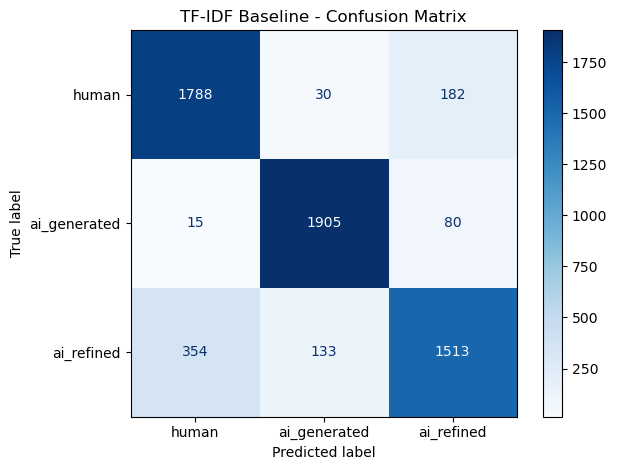


Error counts by true and predicted labels:


prediction,ai_generated,ai_refined,human
label,,,
ai_generated,1905,80,15
ai_refined,133,1513,354
human,30,182,1788



Accuracy by domain:


,count,mean
domain,,
Academic,3000,0.884000
Wiki,3000,0.851333



Accuracy by model:


,count,mean
model,,
deepseek-v3,1500,0.918000
gemini-2.5-flash,1500,0.868667
gpt-4o,1500,0.856667
qwen-max,1500,0.827333


In [7]:
# evaluation

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Quantitative evaluation
y_pred = baseline.predict(test["text"])
y_true = test["label"]

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Test macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 4))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=["human", "ai_generated", "ai_refined"],
    digits=4,
    zero_division=0
))

# 2. Confusion matrix
labels = ["human", "ai_generated", "ai_refined"]

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    values_format="d"
)

plt.title("TF-IDF Baseline - Confusion Matrix")
plt.tight_layout()
plt.show()

# 3. Error distribution
results = test.copy()
results["prediction"] = y_pred
results["correct"] = results["label"] == results["prediction"]

print("\nError counts by true and predicted labels:")
display(pd.crosstab(results["label"], results["prediction"]))

print("\nAccuracy by domain:")
display(results.groupby("domain")["correct"].agg(["count", "mean"]))

print("\nAccuracy by model:")
display(results.groupby("model")["correct"].agg(["count", "mean"]))

In [8]:
import numpy as np
from IPython.display import display

#  QUALITATIVE ANALYSIS

results = results.copy()
results["word_count"] = (
    results["text"].fillna("").str.split().str.len()
)
results["correct"] = (
    results["label"] == results["prediction"]
)

# incorrect classifications

errors = results[~results["correct"]].copy()

selected_errors = []

for (actual, predicted), group in errors.groupby(
    ["label", "prediction"]
):
    # shortest incorrect example
    short = group.nsmallest(1, "word_count").copy()
    short["selection"] = "Shortest incorrect"

    # longest incorrect example
    long = group.drop(short.index).nlargest(
        1, "word_count"
    ).copy()
    long["selection"] = "Longest incorrect"

    # random incorrect example
    remaining = group.drop(
        short.index.union(long.index)
    )
    random_ex = remaining.sample(
        n=min(1, len(remaining)),
        random_state=42
    ).copy()
    random_ex["selection"] = "Random incorrect"

    selected_errors.extend([short, long, random_ex])

incorrect_examples = pd.concat(
    selected_errors, ignore_index=True
)

# correct classification

correct = results[results["correct"]].copy()

correct_examples = (
    correct.groupby("label", group_keys=False)
    .sample(n=1, random_state=42)
    .copy()
)

correct_examples["selection"] = "Random correct"

# combine & display

qualitative_examples = pd.concat(
    [incorrect_examples, correct_examples],
    ignore_index=True
)

for _, row in qualitative_examples.iterrows():
    print("\n" + "=" * 80)
    print("selection:", row["selection"])
    print("actual:", row["label"])
    print("predicted:", row["prediction"])
    print("domain:", row["domain"])
    print("model:", row["model"])
    print("ID:", row["pair_id"])
    print("word count:", row["word_count"])
    print("\nTEXT:")
    print(row["text"])



selection: Shortest incorrect
actual: ai_generated
predicted: ai_refined
domain: Wiki
model: deepseek-v3
ID: 36940
word count: 205

TEXT:
Word of God Christian Academy Word of God Christian Academy (WOGCA) is a private, coeducational Christian school located in Raleigh, North Carolina. Founded in 1993 by Bishop Frank Summerfield—who also established an affiliated church and daycare—the institution serves students from primary through secondary grades. Bishop Summerfield led the school until his passing in 2017. Academic Recognition and Controversies WOGCA has been a notable participant in North Carolina’s school voucher program, which provides state-funded tuition assistance to lower-income students. In 2015, it received the highest allocation of public funds among private schools in the state. However, the school has faced scrutiny over academic standards. In 2006, the NCAA rejected its diplomas due to concerns that the institution might operate as a diploma mill, though the school d